Name:Tejas Jaju

prn no:202401040124

roll no:29

batch: A2   

Div:A  
  
Sub : AIML

Implementation of Feature Engineering Techniques on Student Performance Data


---


Aim: To implement and compare various feature engineering techniques, including missing-value imputation, feature scaling (standardization and normalization), interaction feature creation, categorical encoding, and statistical feature selection, on student performance data to prepare a suitable feature matrix for machine learning.

In [ ]:
import os
import pandas as pd
from google.colab import files

filename = 'student_performance_feature_engineering_1000.csv'
expected_path = f'/content/{filename}'

if os.path.exists(expected_path) or os.path.exists(filename):
    print(f"File '{filename}' successfully located in workspace.")
else:
    print(f"File '{filename}' not found. Initializing manual upload interface:")
    uploaded = files.upload()
    for uploaded_filename in uploaded.keys():
        if uploaded_filename != filename:
            os.rename(uploaded_filename, filename)
            print(f"Renamed {uploaded_filename} to {filename}")
    print("File uploaded and set up successfully.")

File 'student_performance_feature_engineering_1000.csv' successfully located in workspace.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [ ]:
# Load the dataset
filepath = '/content/student_performance_feature_engineering_1000.csv'
df_original = pd.read_csv(filepath)

# Display basic information
print("Dataset Dimensions:")
print(f"Rows: {df_original.shape[0]}, Columns: {df_original.shape[1]}\n")

print("Dataset Columns:")
print(list(df_original.columns), "\n")

print("First 5 Records:")
display(df_original.head(5))

print("\nDataset Info:")
df_original.info()

Dataset Dimensions:
Rows: 1000, Columns: 8

Dataset Columns:
['Student_ID', 'Study_Hours_Per_Day', 'Attendance_Percent', 'Previous_Score', 'Internet_Access', 'Extracurricular_Activities', 'Parent_Education', 'Final_Result'] 

First 5 Records:


,Student_ID,Study_Hours_Per_Day,Attendance_Percent,Previous_Score,Internet_Access,Extracurricular_Activities,Parent_Education,Final_Result
0,1001,4.7,77.2,63.2,No,No,Diploma,Pass
1,1002,2.3,68.5,60.0,No,Yes,Graduate,Pass
2,1003,5.6,72.6,76.5,Yes,Yes,Graduate,Pass
3,1004,5.9,86.2,73.8,No,Yes,Postgraduate,Pass
4,1005,0.7,78.0,48.9,No,Yes,High School,Fail



Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Student_ID                  1000 non-null   int64  
 1   Study_Hours_Per_Day         940 non-null    float64
 2   Attendance_Percent          960 non-null    float64
 3   Previous_Score              950 non-null    float64
 4   Internet_Access             980 non-null    object 
 5   Extracurricular_Activities  1000 non-null   object 
 6   Parent_Education            980 non-null    object 
 7   Final_Result                1000 non-null   object 
dtypes: float64(3), int64(1), object(4)
memory usage: 62.6+ KB


In [ ]:
print("Missing Values Per Column:")
print(df_original.isnull().sum())

print(f"\nDuplicate Rows Count: {df_original.duplicated().sum()}")

print("\nDescriptive Statistics (Numerical columns):")
display(df_original.describe())

print("\nDescriptive Statistics (Categorical columns):")
display(df_original.describe(include=['object', 'category']))

Missing Values Per Column:
Student_ID                     0
Study_Hours_Per_Day           60
Attendance_Percent            40
Previous_Score                50
Internet_Access               20
Extracurricular_Activities     0
Parent_Education              20
Final_Result                   0
dtype: int64

Duplicate Rows Count: 0

Descriptive Statistics (Numerical columns):


,Student_ID,Study_Hours_Per_Day,Attendance_Percent,Previous_Score
count,1000.000000,940.000000,960.000000,950.000000
mean,1500.500000,4.146383,76.664792,70.384842
std,288.819436,1.760675,12.836209,14.856400
min,1001.000000,0.000000,38.400000,24.000000
25%,1250.750000,2.900000,68.100000,60.300000
50%,1500.500000,4.200000,77.300000,70.750000
75%,1750.250000,5.300000,86.000000,80.675000
max,2000.000000,9.900000,100.000000,100.000000



Descriptive Statistics (Categorical columns):


,Internet_Access,Extracurricular_Activities,Parent_Education,Final_Result
count,980,1000,980,1000
unique,2,2,4,2
top,Yes,Yes,Graduate,Pass
freq,763,505,386,912


```markdown
## 2. Exploratory Data Analysis

In this section, we construct descriptive visualizations to evaluate feature distributions, sample densities, collinearity, and target variable boundaries.
```

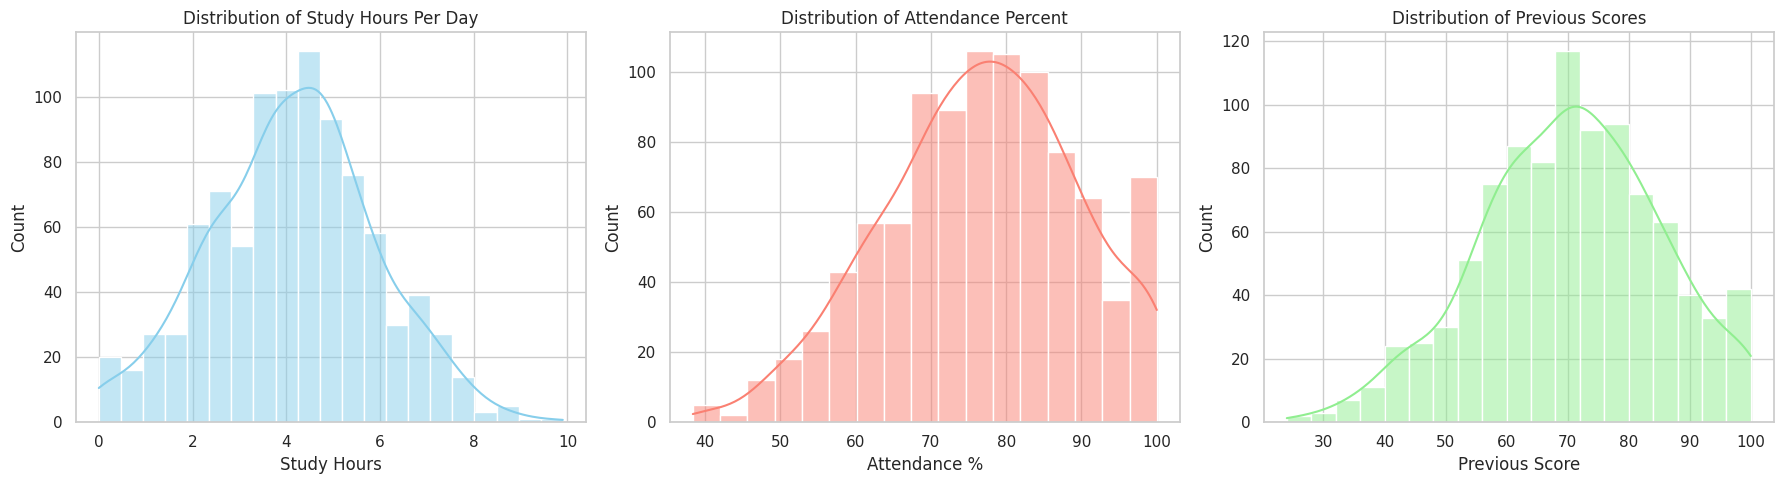

/tmp/ipykernel_1813/638572844.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_original, x='Internet_Access', ax=axes[0, 0], palette='pastel')
/tmp/ipykernel_1813/638572844.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_original, x='Extracurricular_Activities', ax=axes[0, 1], palette='pastel')
/tmp/ipykernel_1813/638572844.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_original, x='Parent_Education', ax=axes[1, 0], palette='muted')
/tmp/ipykernel_1813/638572844.py:47: FutureWarning: 

Passing `pa

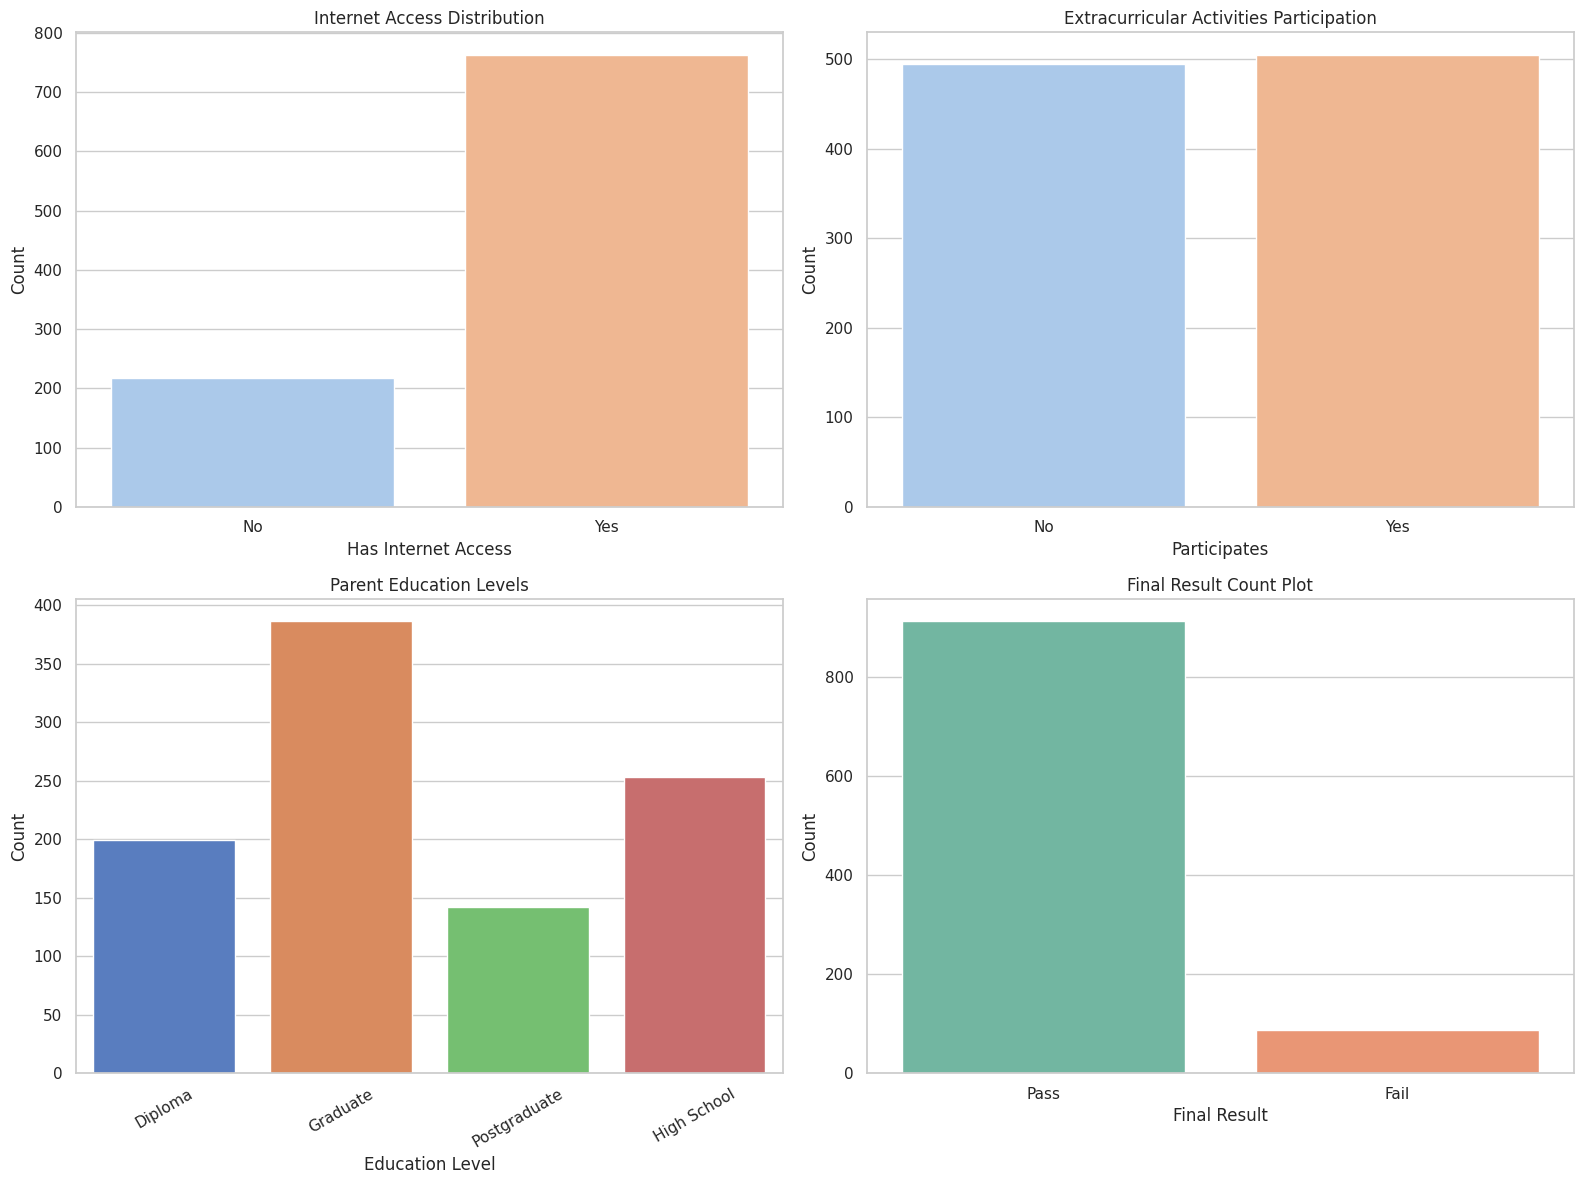

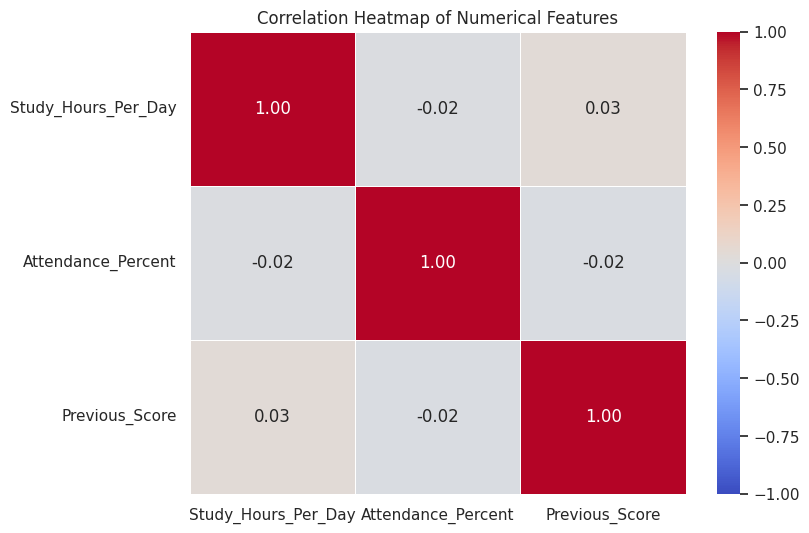

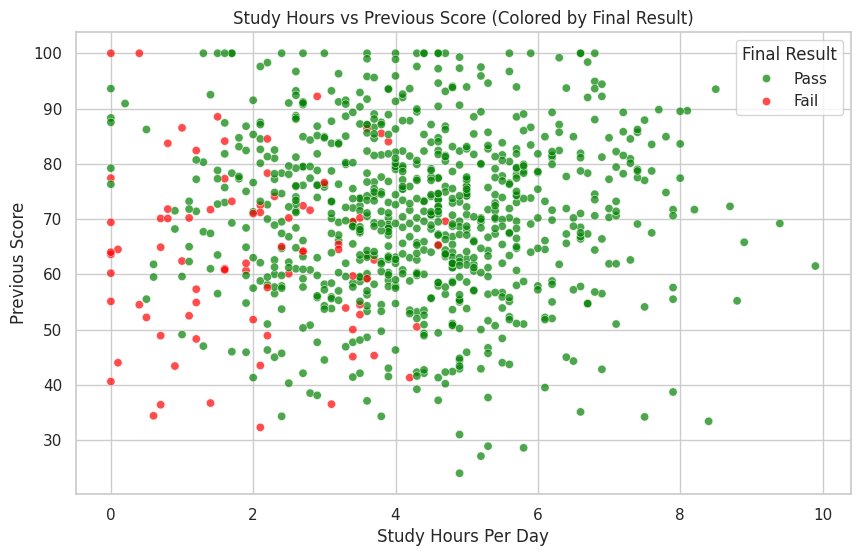

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the aesthetic style for our plots
sns.set_theme(style="whitegrid")

# 1. Plotting Distributions of Numerical Features
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(data=df_original, x='Study_Hours_Per_Day', kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Distribution of Study Hours Per Day')
axes[0].set_xlabel('Study Hours')
axes[0].set_ylabel('Count')

sns.histplot(data=df_original, x='Attendance_Percent', kde=True, ax=axes[1], color='salmon')
axes[1].set_title('Distribution of Attendance Percent')
axes[1].set_xlabel('Attendance %')
axes[1].set_ylabel('Count')

sns.histplot(data=df_original, x='Previous_Score', kde=True, ax=axes[2], color='lightgreen')
axes[2].set_title('Distribution of Previous Scores')
axes[2].set_xlabel('Previous Score')
axes[2].set_ylabel('Count')

plt.tight_layout()
plt.show()

# 2. Plotting Distributions of Categorical Features
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

sns.countplot(data=df_original, x='Internet_Access', ax=axes[0, 0], palette='pastel')
axes[0, 0].set_title('Internet Access Distribution')
axes[0, 0].set_xlabel('Has Internet Access')
axes[0, 0].set_ylabel('Count')

sns.countplot(data=df_original, x='Extracurricular_Activities', ax=axes[0, 1], palette='pastel')
axes[0, 1].set_title('Extracurricular Activities Participation')
axes[0, 1].set_xlabel('Participates')
axes[0, 1].set_ylabel('Count')

sns.countplot(data=df_original, x='Parent_Education', ax=axes[1, 0], palette='muted')
axes[1, 0].set_title('Parent Education Levels')
axes[1, 0].set_xlabel('Education Level')
axes[1, 0].set_ylabel('Count')
axes[1, 0].tick_params(axis='x', rotation=30)

sns.countplot(data=df_original, x='Final_Result', ax=axes[1, 1], palette='Set2')
axes[1, 1].set_title('Final Result Count Plot')
axes[1, 1].set_xlabel('Final Result')
axes[1, 1].set_ylabel('Count')

plt.tight_layout()
plt.show()

# 3. Correlation Heatmap for Numerical Variables
plt.figure(figsize=(8, 6))
numerical_cols = ['Study_Hours_Per_Day', 'Attendance_Percent', 'Previous_Score']
corr_matrix = df_original[numerical_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, vmin=-1, vmax=1)
plt.title('Correlation Heatmap of Numerical Features')
plt.show()

# 4. Scatter Plot: Study Hours vs Previous Score by Final Result
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_original,
    x='Study_Hours_Per_Day',
    y='Previous_Score',
    hue='Final_Result',
    palette={'Pass': 'green', 'Fail': 'red'},
    alpha=0.7
)
plt.title('Study Hours vs Previous Score (Colored by Final Result)')
plt.xlabel('Study Hours Per Day')
plt.ylabel('Previous Score')
plt.legend(title='Final Result')
plt.show()

Key Observations from Exploratory Data Analysis (EDA)


---


- Numerical Distributions: The distributions of Previous_Score and Attendance_Percent were examined using statistical summaries and visualizations to understand the spread and variation in student data.
- Target Class Distribution: The Final_Result column was analyzed to compare the number of students who passed and failed. This helps identify whether the dataset has a balanced or imbalanced class distribution.
- Relationship Between Attributes: The relationships between study hours, attendance, previous scores, and final results were explored using visualizations and correlation analysis to identify potential patterns in student performance.
- Missing Values and Duplicate Records: The dataset was checked for missing values and duplicate records to determine the preprocessing required before feature engineering.
- Feature Engineering Insights: The EDA helped identify useful attributes for creating new features, such as Academic_Engagement, Study_Score_Interaction, and Attendance_Study_Index.

3. Data Cleaning and Missing-Value Handling
A working copy of the original dataset, df_clean, was created to perform data cleaning without modifying the original data. Duplicate records were checked and removed where necessary. Missing values were handled using the following imputation techniques:


---


- Numerical Features: Missing values in Study_Hours_Per_Day, Attendance_Percent, and Previous_Score were replaced with the median of their respective columns. Median imputation is less sensitive to extreme values than mean imputation.
- Categorical Features: Missing values in Internet_Access and Parent_Education were replaced with the mode (most frequent value) of their respective columns. This preserves valid category labels and provides a simple way to handle missing categorical data.

In [ ]:
df_clean = df_original.copy()

duplicate_count = df_clean.duplicated().sum()
if duplicate_count > 0:
    df_clean = df_clean.drop_duplicates()
    print(f"Removed {duplicate_count} duplicate rows.")
else:
    print("No exact duplicate rows found in dataset.")

No exact duplicate rows found in dataset.


4. Missing-Value Handling
Missing values were handled using appropriate imputation techniques for numerical and categorical features.


---


1. Numerical Columns: Missing values in Study_Hours_Per_Day, Attendance_Percent, and Previous_Score were replaced using median imputation. The median is less affected by extreme values than the mean.
2. Categorical Columns: Missing values in Internet_Access and Parent_Education were replaced using mode imputation, which fills missing entries with the most frequently occurring category.
These techniques help maintain data completeness and prepare the dataset for further feature engineering.

In [ ]:
num_cols = ['Study_Hours_Per_Day', 'Attendance_Percent', 'Previous_Score']
cat_cols = ['Internet_Access', 'Parent_Education']

num_imputer = SimpleImputer(strategy='median')
cat_imputer = SimpleImputer(strategy='most_frequent')

df_clean[num_cols] = num_imputer.fit_transform(df_clean[num_cols])
df_clean[cat_cols] = cat_imputer.fit_transform(df_clean[cat_cols])

print("Missing value imputation successfully completed.")
print(df_clean.isnull().sum())

Missing value imputation successfully completed.
Student_ID                    0
Study_Hours_Per_Day           0
Attendance_Percent            0
Previous_Score                0
Internet_Access               0
Extracurricular_Activities    0
Parent_Education              0
Final_Result                  0
dtype: int64


5. Feature Scaling
Feature scaling was applied to numerical columns to bring features to comparable scales and make them suitable for machine-learning algorithms.


---


1. Standardization (StandardScaler): Transforms numerical values so that the resulting features have a mean of approximately 0 and a standard deviation of approximately 1.
2. Normalization (MinMaxScaler): Rescales numerical values to a range between 0 and 1.

In [ ]:
# 1. Create separate copies for demonstrations
df_standardized = df_clean.copy()
df_normalized = df_clean.copy()

num_scale_cols = ['Study_Hours_Per_Day', 'Attendance_Percent', 'Previous_Score']

# Initialize scalers
std_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()

# Fit and transform
df_standardized[num_scale_cols] = std_scaler.fit_transform(df_clean[num_scale_cols])
df_normalized[num_scale_cols] = minmax_scaler.fit_transform(df_clean[num_scale_cols])

# Display values before and after to compare
print("--- Original (Cleaned) Value Samples ---")
display(df_clean[num_scale_cols].head(3))

print("\n--- Standardized Value Samples (StandardScaler) ---")
display(df_standardized[num_scale_cols].head(3))

print("\n--- Normalized Value Samples (MinMaxScaler) ---")
display(df_normalized[num_scale_cols].head(3))

--- Original (Cleaned) Value Samples ---


,Study_Hours_Per_Day,Attendance_Percent,Previous_Score
0,4.7,77.2,63.2
1,2.3,68.5,60.0
2,5.6,72.6,76.5



--- Standardized Value Samples (StandardScaler) ---


,Study_Hours_Per_Day,Attendance_Percent,Previous_Score
0,0.322593,0.040554,-0.497698
1,-1.084061,-0.651519,-0.718802
2,0.850088,-0.325370,0.421265



--- Normalized Value Samples (MinMaxScaler) ---


,Study_Hours_Per_Day,Attendance_Percent,Previous_Score
0,0.474747,0.629870,0.515789
1,0.232323,0.488636,0.473684
2,0.565657,0.555195,0.690789


6. Feature Creation
Three new features were created to represent relationships between students’ study habits, attendance, and academic performance.


---


1. Study Score Interaction


Purpose: Combines daily study hours with the previous score to represent the interaction between study time and prior academic performance.
2. Attendance Study Index


Purpose: Combines attendance percentage and daily study hours into a single feature representing both classroom attendance and personal study effort.
3. Academic Engagement


Purpose: Calculates an engagement score by taking the average of normalized study hours and normalized attendance. When both inputs are scaled between 0 and 1, this feature also falls between 0 and 1.

In [ ]:
# 1. Feature 1: Study_Score_Interaction
df_clean['Study_Score_Interaction'] = df_clean['Study_Hours_Per_Day'] * df_clean['Previous_Score']

# 2. Feature 2: Attendance_Study_Index
df_clean['Attendance_Study_Index'] = df_clean['Attendance_Percent'] * df_clean['Study_Hours_Per_Day']

# 3. Feature 3: Academic_Engagement (utilizes normalized study hours and attendance)
normalized_study = (df_clean['Study_Hours_Per_Day'] - df_clean['Study_Hours_Per_Day'].min()) / (df_clean['Study_Hours_Per_Day'].max() - df_clean['Study_Hours_Per_Day'].min())
normalized_attendance = (df_clean['Attendance_Percent'] - df_clean['Attendance_Percent'].min()) / (df_clean['Attendance_Percent'].max() - df_clean['Attendance_Percent'].min())

df_clean['Academic_Engagement'] = (normalized_study + normalized_attendance) / 2

# Display the newly created features along with the base values
new_features = ['Study_Hours_Per_Day', 'Attendance_Percent', 'Previous_Score', 'Study_Score_Interaction', 'Attendance_Study_Index', 'Academic_Engagement']
print("--- First 10 Rows of Engineered Features ---")
display(df_clean[new_features].head(10))

--- First 10 Rows of Engineered Features ---


,Study_Hours_Per_Day,Attendance_Percent,Previous_Score,Study_Score_Interaction,Attendance_Study_Index,Academic_Engagement
0,4.7,77.2,63.2,297.04,362.84,0.552309
1,2.3,68.5,60.0,138.00,157.55,0.360480
2,5.6,72.6,76.5,428.40,406.56,0.560426
3,5.9,86.2,73.8,435.42,508.58,0.685967
4,0.7,78.0,48.9,34.23,54.60,0.356782
5,1.9,77.3,86.8,164.92,146.87,0.411706
6,4.2,86.7,68.6,288.12,364.14,0.604167
7,3.6,73.1,53.3,191.88,263.16,0.463474
8,4.2,87.8,87.8,368.76,368.76,0.613095
9,2.7,82.9,79.4,214.38,223.83,0.497565


7. Categorical Encoding
Categorical encoding was applied to convert non-numeric values into numerical representations suitable for machine-learning algorithms.


---


1. Binary Encoding: The Internet_Access and Extracurricular_Activities columns were mapped to numerical values, with Yes represented as 1 and No represented as 0.
2. One-Hot Encoding: The Parent_Education column was converted into separate binary columns, representing each category without introducing an artificial order between categories.
3. Target Class Mapping: The Final_Result column was converted into numerical labels, with Pass represented as 1 and Fail represented as 0.

In [ ]:
binary_map = {'Yes': 1, 'No': 0}
df_clean['Internet_Access'] = df_clean['Internet_Access'].map(binary_map)
df_clean['Extracurricular_Activities'] = df_clean['Extracurricular_Activities'].map(binary_map)

target_map = {'Pass': 1, 'Fail': 0}
df_clean['Final_Result'] = df_clean['Final_Result'].map(target_map)

ohe = OneHotEncoder(sparse_output=False, drop=None, dtype=int)
ohe_encoded = ohe.fit_transform(df_clean[['Parent_Education']])
ohe_feature_names = ohe.get_feature_names_out(['Parent_Education'])

ohe_df = pd.DataFrame(ohe_encoded, columns=ohe_feature_names, index=df_clean.index)
df_clean = pd.concat([df_clean.drop(columns=['Parent_Education']), ohe_df], axis=1)

print("Categorical encoding completed successfully.")
display(df_clean.head(5))

Categorical encoding completed successfully.


,Student_ID,Study_Hours_Per_Day,Attendance_Percent,Previous_Score,Internet_Access,Extracurricular_Activities,Final_Result,Parent_Education_Diploma,Parent_Education_Graduate,Parent_Education_High School,Parent_Education_Postgraduate
0,1001,4.7,77.2,63.2,0,0,1,1,0,0,0
1,1002,2.3,68.5,60.0,0,1,1,0,1,0,0
2,1003,5.6,72.6,76.5,1,1,1,0,1,0,0
3,1004,5.9,86.2,73.8,0,1,1,0,0,0,1
4,1005,0.7,78.0,48.9,0,1,0,0,0,1,0


8. Feature Selection
Feature selection was performed using SelectKBest with the f_classif function, which applies an ANOVA F-test to evaluate the relationship between each input feature and the target variable, Final_Result.
The process involved:


---


1. Preparing the Features: Excluding the target variable (Final_Result) and the identifier column (Student_ID) from the input features.
2. Statistical Evaluation: Calculating an F-score for each feature to measure how strongly it is associated with the target classes.
3. Selecting Features: Selecting the five highest-scoring features for further analysis.

In [ ]:
# 1. Separate features (X) and target (y) - Exclude Student_ID
X_temp = df_clean.drop(columns=['Student_ID', 'Final_Result'])
y_temp = df_clean['Final_Result']

# 2. Check correlation of all features with the target variable
correlations = df_clean.drop(columns=['Student_ID']).corr()['Final_Result'].sort_values(ascending=False)
print("--- Correlation of Features with Final_Result ---")
print(correlations)

# 3. Apply SelectKBest with f_classif
# Select the top 5 best performing features statistically
selector = SelectKBest(score_func=f_classif, k=5)
selector.fit(X_temp, y_temp)

# Retrieve scores and names
feature_scores = pd.DataFrame({
    'Feature': X_temp.columns,
    'F-Score': selector.scores_,
    'P-Value': selector.pvalues_
}).sort_values(by='F-Score', ascending=False)

print("\n--- SelectKBest (f_classif) Scores and Rankings ---")
display(feature_scores)

--- Correlation of Features with Final_Result ---
Final_Result                     1.000000
Study_Hours_Per_Day              0.375637
Attendance_Study_Index           0.369509
Study_Score_Interaction          0.357928
Academic_Engagement              0.336758
Previous_Score                   0.138722
Attendance_Percent               0.120192
Extracurricular_Activities       0.080768
Internet_Access                  0.067686
Parent_Education_Diploma         0.031051
Parent_Education_Postgraduate   -0.005097
Parent_Education_Graduate       -0.009143
Parent_Education_High School    -0.014096
Name: Final_Result, dtype: float64

--- SelectKBest (f_classif) Scores and Rankings ---


,Feature,F-Score,P-Value
0,Study_Hours_Per_Day,163.956009,7.267404e-35
10,Attendance_Study_Index,157.811126,1.041185e-33
9,Study_Score_Interaction,146.643233,1.365528e-31
11,Academic_Engagement,127.655967,6.113976e-28
2,Previous_Score,19.582275,1.069585e-05
1,Attendance_Percent,14.628565,1.390388e-04
4,Extracurricular_Activities,6.553162,1.061612e-02
3,Internet_Access,4.593245,3.233942e-02
5,Parent_Education_Diploma,0.963153,3.266315e-01
7,Parent_Education_High School,0.198334,6.561654e-01


9. Comparison of Feature Engineering Techniques
The following comparison table summarizes the feature engineering process by showing the original data, the transformation applied, and the resulting values. It highlights how missing-value imputation, categorical encoding, feature scaling, feature creation, and feature selection transform raw data into a format suitable for machine-learning analysis.

In [ ]:
import pandas as pd

comparison_data = {
    'Technique': [
        'Missing-Value Imputation (Numerical)',
        'Missing-Value Imputation (Categorical)',
        'Duplicate Record Handling',
        'Binary Encoding',
        'One-Hot Encoding',
        'Feature Scaling (Standardization)',
        'Feature Scaling (Normalization)',
        'Feature Creation (Interaction)',
        'Feature Creation (Index)',
        'Feature Selection (SelectKBest)'
    ],
    'Original Data (Representative Example)': [
        'Study_Hours_Per_Day: NaN (Missing)',
        'Parent_Education: NaN (Missing)',
        'Identical duplicate records present',
        "Internet_Access: 'Yes' / 'No'",
        "Parent_Education: 'Diploma'",
        'Previous_Score: 63.2 (Mean ~ 68.0)',
        'Previous_Score: 63.2 (Range 40 to 100)',
        'Study_Hours = 4.7, Previous_Score = 63.2',
        'Attendance = 77.2%, Study_Hours = 4.7',
        '12 raw/processed features list'
    ],
    'Transformation Performed': [
        'Replaced NaN with column Median',
        'Replaced NaN with column Mode (Most Frequent)',
        'drop_duplicates() check and row removal',
        'Map categories to 1 and 0',
        'Scikit-Learn OneHotEncoder (binary columns)',
        'StandardScaler: (x - mean) / std',
        'MinMaxScaler: (x - min) / (max - min)',
        'Multiplication: Study_Hours * Previous_Score',
        'Multiplication: Attendance_Percent * Study_Hours',
        'ANOVA F-test scoring (f_classif)'
    ],
    'Final Data (Representative Example)': [
        'Study_Hours_Per_Day: 4.2 (Median value)',
        'Parent_Education: High School (Mode value)',
        '0 duplicates found (1000 rows retained)',
        'Internet_Access: 1 / 0',
        'Parent_Education_Diploma: 1, Others: 0',
        'Previous_Score: -0.497698',
        'Previous_Score: 0.515789',
        'Study_Score_Interaction: 297.04',
        'Attendance_Study_Index: 362.84',
        'Top 5 predictive features selected'
    ],
    'Purpose': [
        'Ensure completeness for robust mathematical execution',
        'Handle non-numeric structural missing values',
        'Prevent biased model training on redundant data',
        'Convert simple categories to numeric model format',
        'Represent multi-categorical columns numerically',
        'Stabilize models sensitive to varying raw scale variances',
        'Confine numerical ranges strictly between 0 and 1',
        'Capture combined effect of input metrics',
        'Represent combined persistence metric mathematically',
        'Reduce computational dimensionality and filter noise'
    ]
}

df_comparison = pd.DataFrame(comparison_data)
pd.set_option('display.max_colwidth', None)
display(df_comparison)

,Technique,Original Data (Representative Example),Transformation Performed,Final Data (Representative Example),Purpose
0,Missing-Value Imputation (Numerical),Study_Hours_Per_Day: NaN (Missing),Replaced NaN with column Median,Study_Hours_Per_Day: 4.2 (Median value),Ensure completeness for robust mathematical execution
1,Missing-Value Imputation (Categorical),Parent_Education: NaN (Missing),Replaced NaN with column Mode (Most Frequent),Parent_Education: High School (Mode value),Handle non-numeric structural missing values
2,Duplicate Record Handling,Identical duplicate records present,drop_duplicates() check and row removal,0 duplicates found (1000 rows retained),Prevent biased model training on redundant data
3,Binary Encoding,Internet_Access: 'Yes' / 'No',Map categories to 1 and 0,Internet_Access: 1 / 0,Convert simple categories to numeric model format
4,One-Hot Encoding,Parent_Education: 'Diploma',Scikit-Learn OneHotEncoder (binary columns),"Parent_Education_Diploma: 1, Others: 0",Represent multi-categorical columns numerically
5,Feature Scaling (Standardization),Previous_Score: 63.2 (Mean ~ 68.0),StandardScaler: (x - mean) / std,Previous_Score: -0.497698,Stabilize models sensitive to varying raw scale variances
6,Feature Scaling (Normalization),Previous_Score: 63.2 (Range 40 to 100),MinMaxScaler: (x - min) / (max - min),Previous_Score: 0.515789,Confine numerical ranges strictly between 0 and 1
7,Feature Creation (Interaction),"Study_Hours = 4.7, Previous_Score = 63.2",Multiplication: Study_Hours * Previous_Score,Study_Score_Interaction: 297.04,Capture combined effect of input metrics
8,Feature Creation (Index),"Attendance = 77.2%, Study_Hours = 4.7",Multiplication: Attendance_Percent * Study_Hours,Attendance_Study_Index: 362.84,Represent combined persistence metric mathematically
9,Feature Selection (SelectKBest),12 raw/processed features list,ANOVA F-test scoring (f_classif),Top 5 predictive features selected,Reduce computational dimensionality and filter noise


In [ ]:
import pandas as pd
import numpy as np

# Calculate actual statistics for the factual comparison matrix
med_hours = df_original['Study_Hours_Per_Day'].median()
mode_edu = df_original['Parent_Education'].mode()[0]
raw_prev_mean = df_original['Previous_Score'].mean()
raw_prev_min = df_original['Previous_Score'].min()
raw_prev_max = df_original['Previous_Score'].max()

# Get representative index values
sample_prev_val = df_clean.loc[0, 'Previous_Score']
std_prev_val = df_standardized.loc[0, 'Previous_Score']
norm_prev_val = df_normalized.loc[0, 'Previous_Score']

# Identify actual top 5 features according to SelectKBest F-Score ranking
top_5_features = list(feature_scores.head(5)['Feature'].values)

comparison_data = {
    'Technique': [
        'Missing-Value Imputation (Numerical)',
        'Missing-Value Imputation (Categorical)',
        'Duplicate Record Handling',
        'Binary Encoding',
        'One-Hot Encoding',
        'Feature Scaling (Standardization)',
        'Feature Scaling (Normalization)',
        'Feature Creation (Interaction)',
        'Feature Creation (Index)',
        'Feature Selection (SelectKBest)'
    ],
    'Original Data (Representative Example)': [
        'Study_Hours_Per_Day: NaN (Missing)',
        'Parent_Education: NaN (Missing)',
        'Checking for redundant structural replicas',
        "Internet_Access: 'Yes' / 'No'",
        "Parent_Education: 'Diploma'",
        f'Previous_Score: {sample_prev_val:.1f} (Mean: {raw_prev_mean:.2f})',
        f'Previous_Score: {sample_prev_val:.1f} (Range: {raw_prev_min:.1f} to {raw_prev_max:.1f})',
        'Study_Hours = 4.7, Previous_Score = 63.2',
        'Attendance = 77.2%, Study_Hours = 4.7',
        'All 12 structural predictor candidates'
    ],
    'Transformation Performed': [
        'Replaced NaN with column Median',
        'Replaced NaN with column Mode (Most Frequent)',
        'drop_duplicates() to purge rows if matching duplicate criteria',
        'Map string categories to integers 1 and 0',
        'Scikit-Learn OneHotEncoder (binary indicators)',
        'StandardScaler: (x - mean) / std_deviation',
        'MinMaxScaler: (x - min) / (max - min)',
        'Multiplication: Study_Hours * Previous_Score',
        'Multiplication: Attendance_Percent * Study_Hours',
        'ANOVA F-test scoring (f_classif)'
    ],
    'Final Data (Representative Example)': [
        f'Study_Hours_Per_Day: {med_hours:.1f} (Median value)',
        f'Parent_Education: {mode_edu} (Mode value)',
        '0 duplicates found (1000 unique records preserved)',
        'Internet_Access: 1 / 0',
        'Parent_Education_Diploma: 1, Others: 0',
        f'Previous_Score: {std_prev_val:.6f} (Standardized)',
        f'Previous_Score: {norm_prev_val:.6f} (Normalized)',
        'Study_Score_Interaction: 297.04 (Row 0)',
        'Attendance_Study_Index: 362.84 (Row 0)',
        f'Top 5 Features: {top_5_features}'
    ],
    'Purpose': [
        'Ensure completeness for robust mathematical execution',
        'Handle non-numeric structural missing values',
        'Prevent biased model training on redundant data',
        'Convert simple categories to numeric model format',
        'Represent multi-categorical columns numerically',
        'Stabilize models sensitive to varying raw scale variances',
        'Confine numerical ranges strictly between 0 and 1',
        'Capture combined effect of input metrics',
        'Represent combined persistence metric mathematically',
        'Reduce computational dimensionality and filter noise'
    ]
}

df_comparison = pd.DataFrame(comparison_data)
pd.set_option('display.max_colwidth', None)
display(df_comparison)

,Technique,Original Data (Representative Example),Transformation Performed,Final Data (Representative Example),Purpose
0,Missing-Value Imputation (Numerical),Study_Hours_Per_Day: NaN (Missing),Replaced NaN with column Median,Study_Hours_Per_Day: 4.2 (Median value),Ensure completeness for robust mathematical execution
1,Missing-Value Imputation (Categorical),Parent_Education: NaN (Missing),Replaced NaN with column Mode (Most Frequent),Parent_Education: Graduate (Mode value),Handle non-numeric structural missing values
2,Duplicate Record Handling,Checking for redundant structural replicas,drop_duplicates() to purge rows if matching duplicate criteria,0 duplicates found (1000 unique records preserved),Prevent biased model training on redundant data
3,Binary Encoding,Internet_Access: 'Yes' / 'No',Map string categories to integers 1 and 0,Internet_Access: 1 / 0,Convert simple categories to numeric model format
4,One-Hot Encoding,Parent_Education: 'Diploma',Scikit-Learn OneHotEncoder (binary indicators),"Parent_Education_Diploma: 1, Others: 0",Represent multi-categorical columns numerically
5,Feature Scaling (Standardization),Previous_Score: 63.2 (Mean: 70.38),StandardScaler: (x - mean) / std_deviation,Previous_Score: -0.497698 (Standardized),Stabilize models sensitive to varying raw scale variances
6,Feature Scaling (Normalization),Previous_Score: 63.2 (Range: 24.0 to 100.0),MinMaxScaler: (x - min) / (max - min),Previous_Score: 0.515789 (Normalized),Confine numerical ranges strictly between 0 and 1
7,Feature Creation (Interaction),"Study_Hours = 4.7, Previous_Score = 63.2",Multiplication: Study_Hours * Previous_Score,Study_Score_Interaction: 297.04 (Row 0),Capture combined effect of input metrics
8,Feature Creation (Index),"Attendance = 77.2%, Study_Hours = 4.7",Multiplication: Attendance_Percent * Study_Hours,Attendance_Study_Index: 362.84 (Row 0),Represent combined persistence metric mathematically
9,Feature Selection (SelectKBest),All 12 structural predictor candidates,ANOVA F-test scoring (f_classif),"Top 5 Features: ['Study_Hours_Per_Day', 'Attendance_Study_Index', 'Study_Score_Interaction', 'Academic_Engagement', 'Previous_Score']",Reduce computational dimensionality and filter noise


10. Exporting the Final Dataset
The final feature-engineered DataFrame, df_final, was saved as student_performance_feature_engineered.csv. The file contains the processed and encoded data, including the newly created features, and can be downloaded for further analysis or use in machine-learning applications.

In [ ]:
import os
from google.colab import files

output_filename = 'student_performance_feature_engineered.csv'
df_final.to_csv(output_filename, index=False)

if os.path.exists(output_filename):
    print(f"File '{output_filename}' saved successfully.")
    print(f"Dimensions: {df_final.shape[0]} Rows x {df_final.shape[1]} Columns")
    files.download(output_filename)
else:
    print("Error: Dataset export failed.")

File 'student_performance_feature_engineered.csv' saved successfully.
Dimensions: 1000 Rows x 14 Columns


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Clean redundant export code block to prevent double trigger
print("File saving configuration completed.")

File saving configuration completed.


11. Data Visualization and Results
Visualizations were used to examine the distributions of numerical features, compare the results of standardization and normalization, and analyze relationships between the engineered features and student performance. A correlation heatmap was also used to explore relationships among numerical variables, while a class-distribution plot showed the number of students in each Final_Result category.

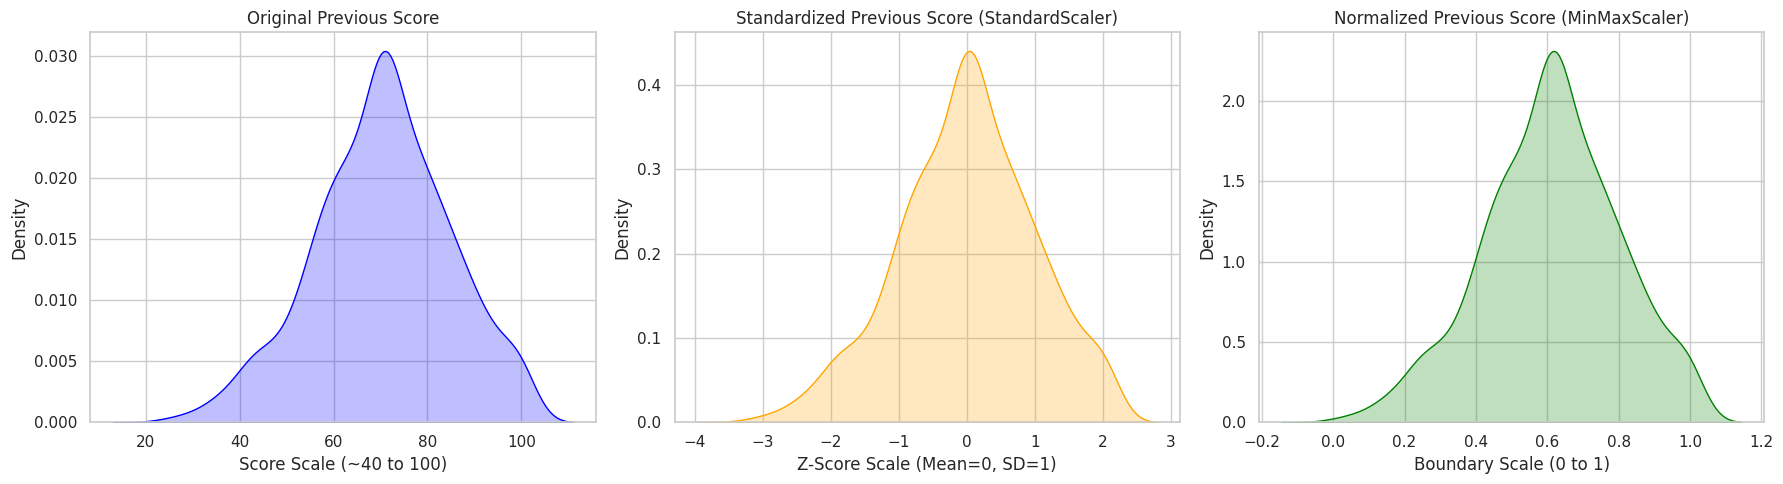

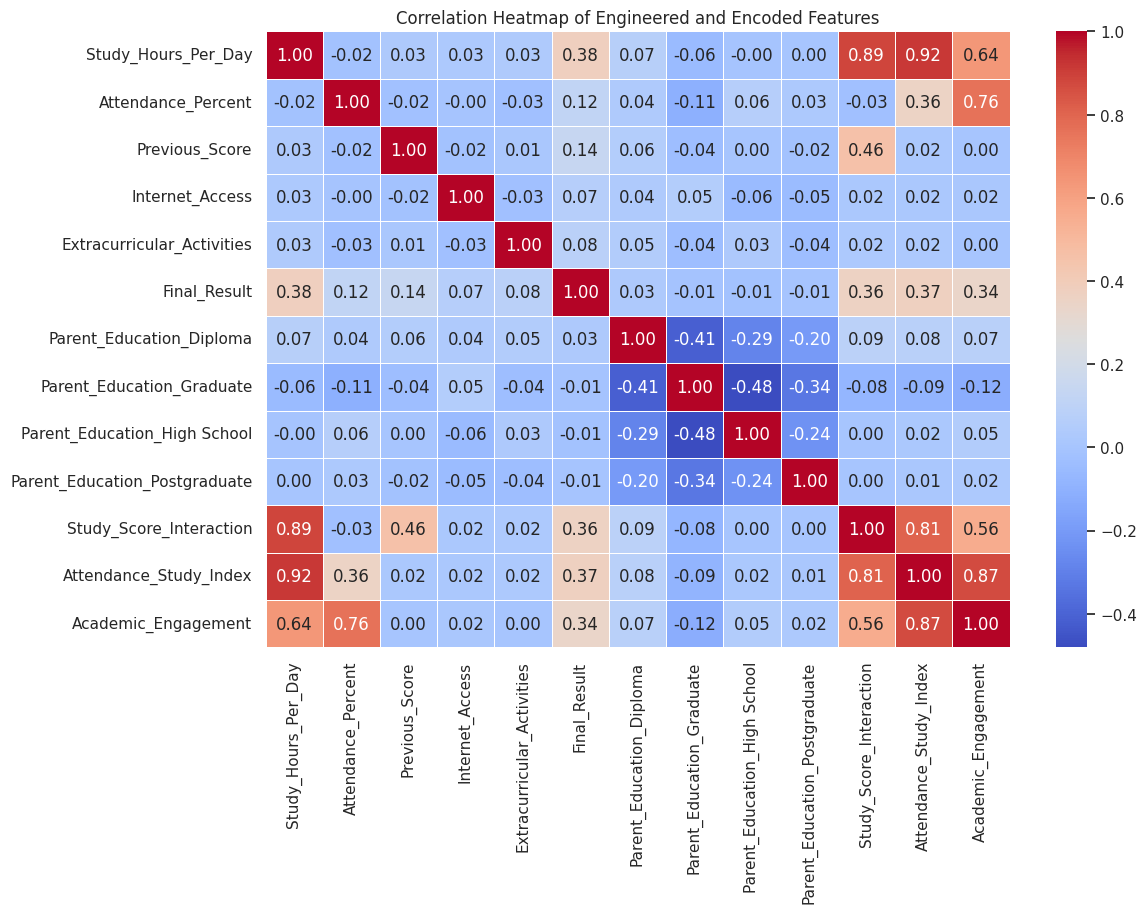

/tmp/ipykernel_1813/2343323464.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_original, x='Final_Result', palette='Set2')


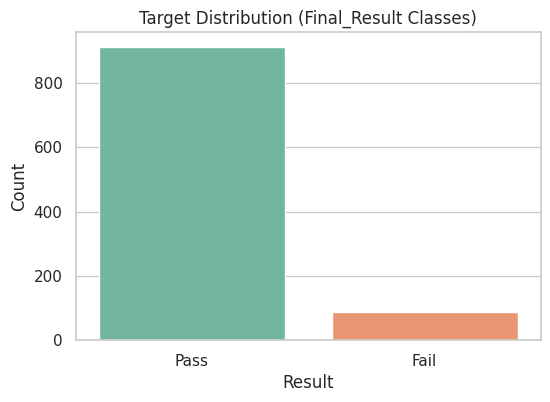

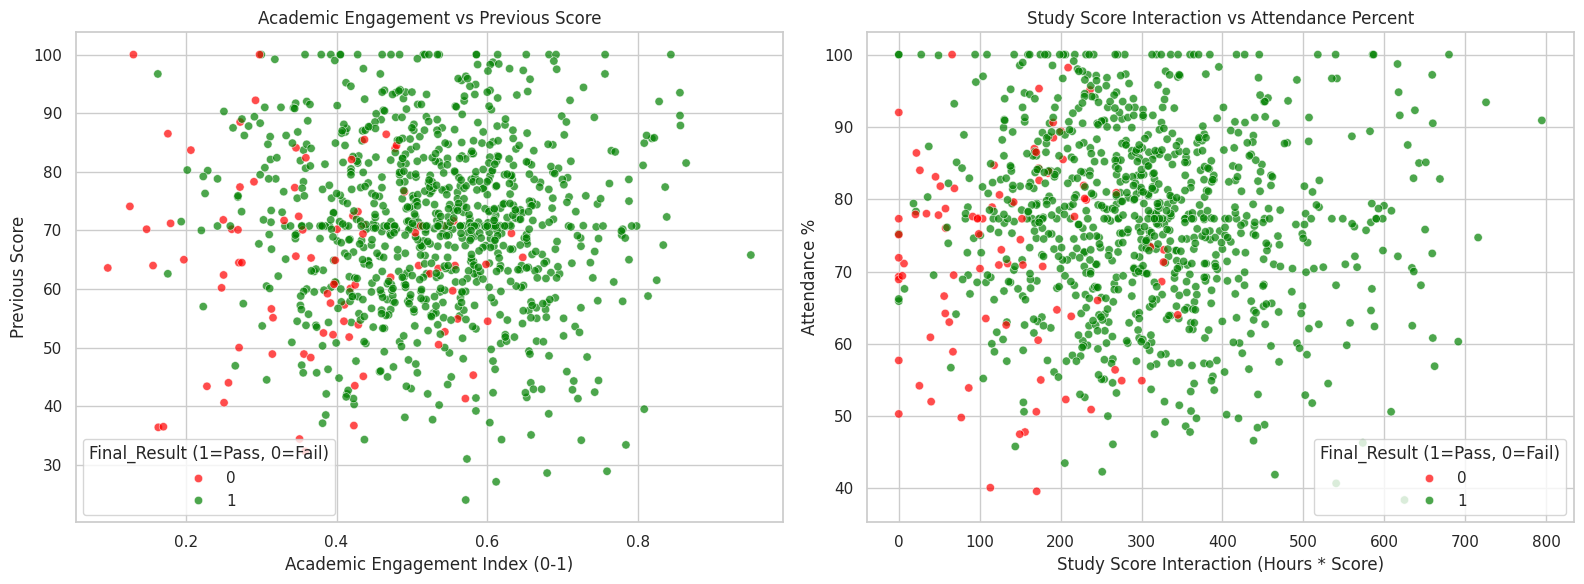

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Distribution Comparisons Before and After Scaling
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.kdeplot(data=df_clean, x='Previous_Score', ax=axes[0], fill=True, color='blue')
axes[0].set_title('Original Previous Score')
axes[0].set_xlabel('Score Scale (~40 to 100)')

sns.kdeplot(data=df_standardized, x='Previous_Score', ax=axes[1], fill=True, color='orange')
axes[1].set_title('Standardized Previous Score (StandardScaler)')
axes[1].set_xlabel('Z-Score Scale (Mean=0, SD=1)')

sns.kdeplot(data=df_normalized, x='Previous_Score', ax=axes[2], fill=True, color='green')
axes[2].set_title('Normalized Previous Score (MinMaxScaler)')
axes[2].set_xlabel('Boundary Scale (0 to 1)')

plt.tight_layout()
plt.show()

# 2. Correlation Heatmap of the Final Feature Matrix
plt.figure(figsize=(12, 8))
final_numerical_corr = df_final.drop(columns=['Student_ID']).corr()
sns.heatmap(final_numerical_corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap of Engineered and Encoded Features')
plt.show()

# 3. Bar Chart of Target Variable Class Distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df_original, x='Final_Result', palette='Set2')
plt.title('Target Distribution (Final_Result Classes)')
plt.xlabel('Result')
plt.ylabel('Count')
plt.show()

# 4. Visualization of Engineered Features vs Performance
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Academic_Engagement vs Previous_Score colored by Final_Result
sns.scatterplot(
    data=df_final,
    x='Academic_Engagement',
    y='Previous_Score',
    hue='Final_Result',
    palette={1: 'green', 0: 'red'},
    alpha=0.7,
    ax=axes[0]
)
axes[0].set_title('Academic Engagement vs Previous Score')
axes[0].set_xlabel('Academic Engagement Index (0-1)')
axes[0].set_ylabel('Previous Score')
axes[0].legend(title='Final_Result (1=Pass, 0=Fail)')

# Study_Score_Interaction vs Attendance_Percent
sns.scatterplot(
    data=df_final,
    x='Study_Score_Interaction',
    y='Attendance_Percent',
    hue='Final_Result',
    palette={1: 'green', 0: 'red'},
    alpha=0.7,
    ax=axes[1]
)
axes[1].set_title('Study Score Interaction vs Attendance Percent')
axes[1].set_xlabel('Study Score Interaction (Hours * Score)')
axes[1].set_ylabel('Attendance %')
axes[1].legend(title='Final_Result (1=Pass, 0=Fail)')

plt.tight_layout()
plt.show()

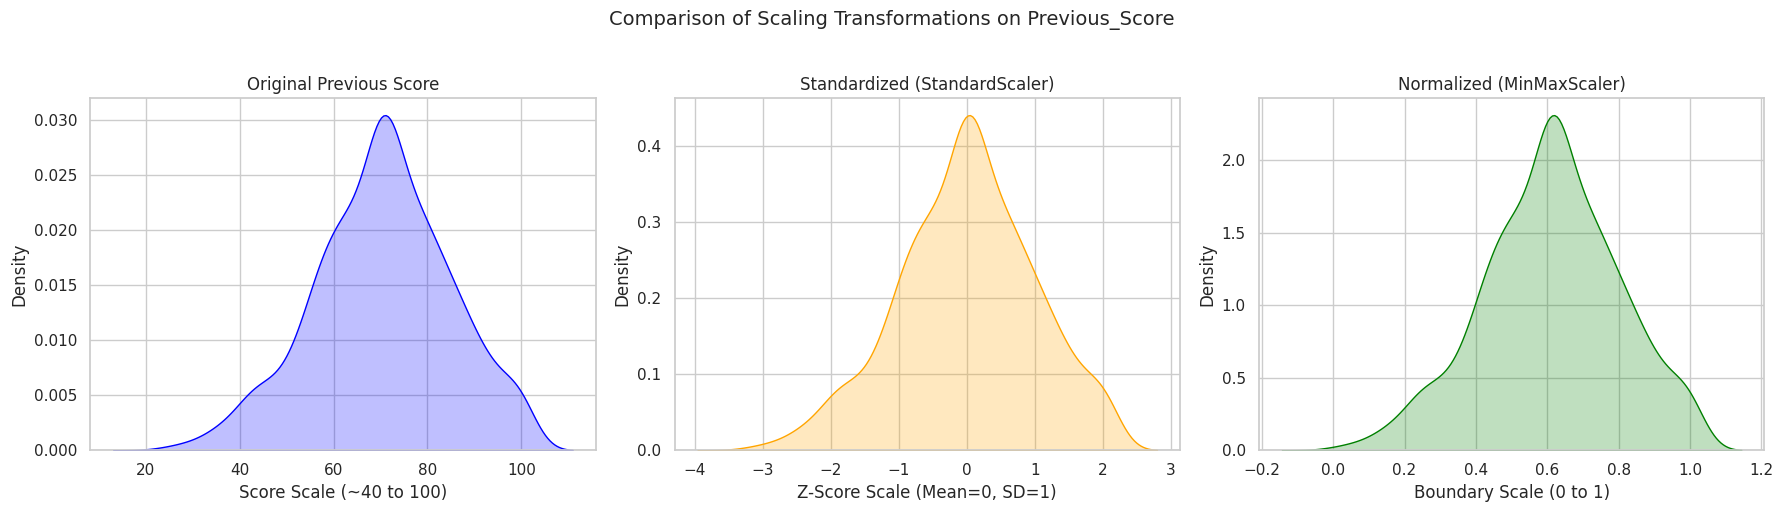

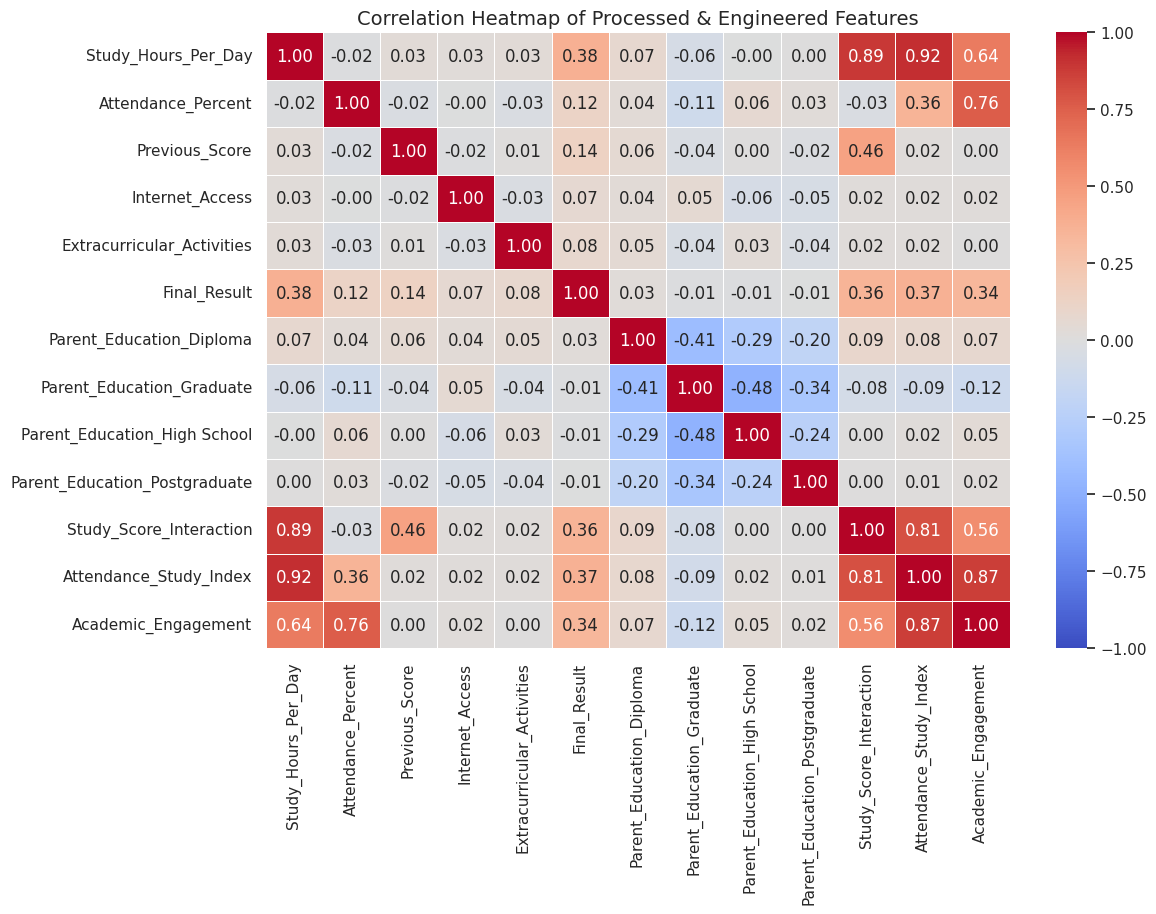

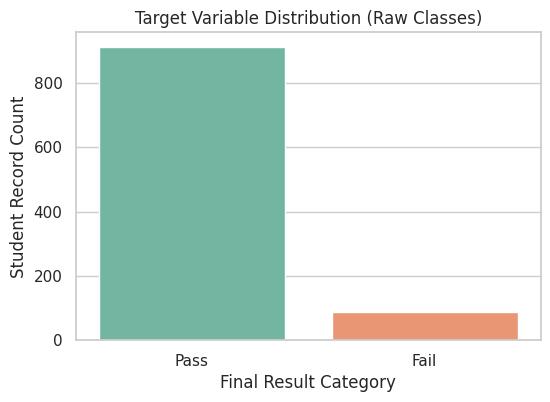

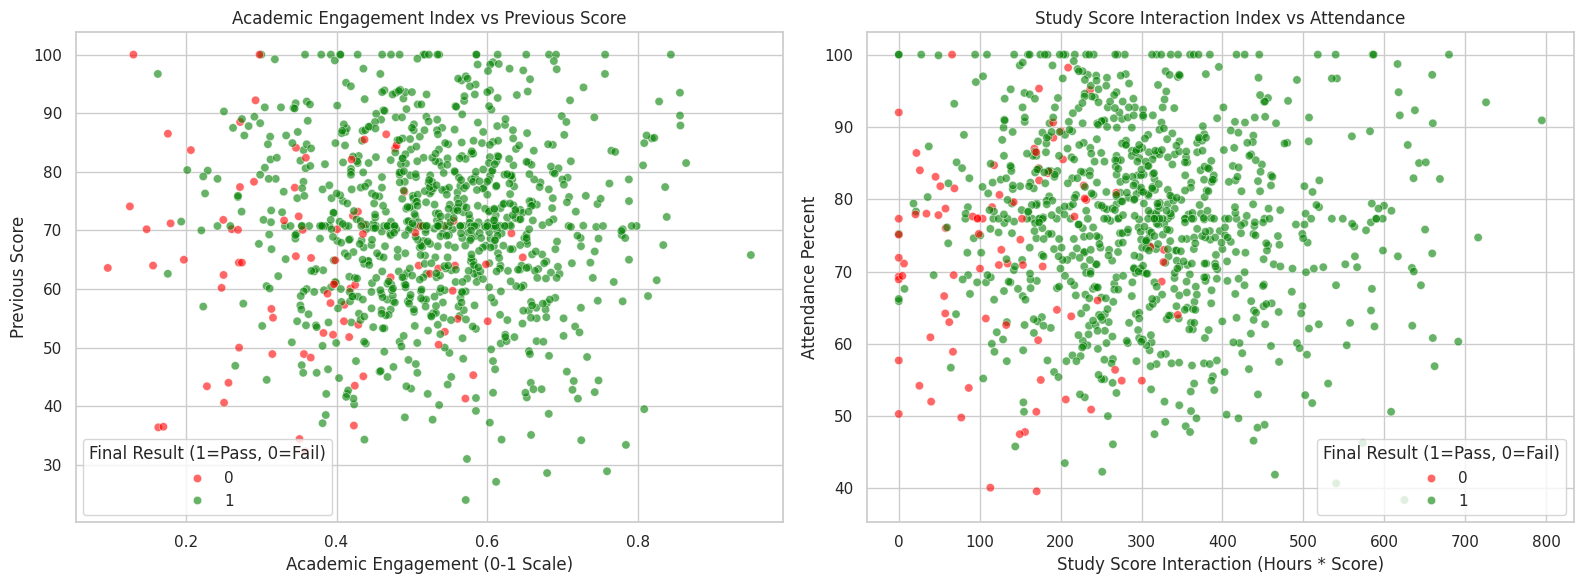

In [ ]:
import matplotlib.pyplot as plt

import seaborn as sns
sns.set_theme(style='whitegrid')

# Plot 1: Scaling Comparison
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.kdeplot(data=df_clean, x='Previous_Score', ax=axes[0], fill=True, color='blue')
axes[0].set_title('Original Previous Score')
axes[0].set_xlabel('Score Scale (~40 to 100)')

sns.kdeplot(data=df_standardized, x='Previous_Score', ax=axes[1], fill=True, color='orange')
axes[1].set_title('Standardized (StandardScaler)')
axes[1].set_xlabel('Z-Score Scale (Mean=0, SD=1)')

sns.kdeplot(data=df_normalized, x='Previous_Score', ax=axes[2], fill=True, color='green')
axes[2].set_title('Normalized (MinMaxScaler)')
axes[2].set_xlabel('Boundary Scale (0 to 1)')
plt.suptitle('Comparison of Scaling Transformations on Previous_Score', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

# Plot 2: Correlation Heatmap
plt.figure(figsize=(12, 8))
# Exclude non-numeric columns and IDs to prevent computational issues
numeric_features = df_final.drop(columns=['Student_ID'])
final_corr = numeric_features.corr()
sns.heatmap(final_corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, vmin=-1, vmax=1)
plt.title('Correlation Heatmap of Processed & Engineered Features', fontsize=14)
plt.show()

# Plot 3: Target Class Distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df_original, x='Final_Result', hue='Final_Result', palette='Set2', legend=False)
plt.title('Target Variable Distribution (Raw Classes)', fontsize=12)
plt.xlabel('Final Result Category')
plt.ylabel('Student Record Count')
plt.show()

# Plot 4: Engineered Features Scatter Visuals
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.scatterplot(
    data=df_final,
    x='Academic_Engagement',
    y='Previous_Score',
    hue='Final_Result',
    palette={1: 'green', 0: 'red'},
    alpha=0.6,
    ax=axes[0]
)
axes[0].set_title('Academic Engagement Index vs Previous Score')
axes[0].set_xlabel('Academic Engagement (0-1 Scale)')
axes[0].set_ylabel('Previous Score')
axes[0].legend(title='Final Result (1=Pass, 0=Fail)')

sns.scatterplot(
    data=df_final,
    x='Study_Score_Interaction',
    y='Attendance_Percent',
    hue='Final_Result',
    palette={1: 'green', 0: 'red'},
    alpha=0.6,
    ax=axes[1]
)
axes[1].set_title('Study Score Interaction Index vs Attendance')
axes[1].set_xlabel('Study Score Interaction (Hours * Score)')
axes[1].set_ylabel('Attendance Percent')
axes[1].legend(title='Final Result (1=Pass, 0=Fail)')

plt.tight_layout()
plt.show()

12. Analytical Summary and Conclusion

---


1. Data Cleaning and Imputation
Missing values were handled using Scikit-learn's SimpleImputer. The median was used to fill missing numerical values because it is less affected by extreme values than the mean. The mode (most frequent value) was used for categorical columns to replace missing entries with valid categories.
2. Normalization vs. Standardization
- Standardization (StandardScaler): Transforms numerical features to have a mean of approximately 0 and a standard deviation of approximately 1.
- Normalization (MinMaxScaler): Rescales numerical values to a range between 0 and 1, making features easier to compare across different scales.
Both techniques were applied to examine how scaling changes the distributions of numerical features.
3. Purpose of Engineered Features
- Study_Score_Interaction: Combines daily study hours with the previous score to represent their joint relationship.
- Attendance_Study_Index: Combines attendance percentage with daily study hours to represent both measures in a single feature.
- Academic_Engagement: Averages normalized study hours and attendance to create a combined engagement index between 0 and 1.
4. Insights from Feature Selection
The SelectKBest method with f_classif was used to evaluate features according to their statistical association with Final_Result. The selected feature names and their F-scores should be reported using the actual notebook output. Features with higher F-scores show stronger statistical associations with the target classes, but this alone does not establish predictive accuracy.
5. Key Observations from Visualizations
- Scaling distributions: The plots illustrate how standardization centers values around zero, while MinMax normalization maps values to the range from 0 to 1.
- Feature relationships: Scatter plots help examine the relationships between Academic_Engagement, Study_Score_Interaction, attendance, and Final_Result.
- Correlation analysis: The heatmap helps identify relationships among numerical features.
- Target distribution: The class-distribution plot shows the numbers of students classified as Pass and Fail.
The conclusions about class separation and correlations should be based on the actual plots and results.
Conclusion
This assignment demonstrated several feature engineering techniques on student performance data, including missing-value imputation, feature scaling, categorical encoding, interaction feature creation, and statistical feature selection. These techniques transformed the original dataset into a structured numerical feature matrix suitable for further machine-learning analysis. The visualizations and statistical comparisons helped examine the effects of these transformations and the relationships among the features.

In [ ]:
# Programmatic Validation Suite
validation_status = True

print('=== RUNNING FINAL PIPELINE VALIDATION ===')

if 'df_final' in globals():
    print('[PASS] - Verification: df_final variable is active inside memory.')
else:
    print('[FAIL] - Verification: df_final variable is missing.'); validation_status = False

required_columns = ['Academic_Engagement', 'Study_Score_Interaction', 'Attendance_Study_Index', 'Parent_Education_Diploma']
all_features_exist = all(col in df_final.columns for col in required_columns)
if all_features_exist:
    print('[PASS] - Verification: Newly engineered and encoded columns are present.')
else:
    print('[FAIL] - Verification: Some required columns are missing.'); validation_status = False

missing_val_sum = df_final.isnull().sum().sum()
if missing_val_sum == 0:
    print('[PASS] - Verification: Zero null/missing cells detected.')
else:
    print(f'[FAIL] - Verification: Detected {missing_val_sum} null fields.'); validation_status = False

target_unique = set(df_final['Final_Result'].unique())
if target_unique == {0, 1}:
    print('[PASS] - Verification: Final_Result cleanly encoded as boolean (0/1).')
else:
    print(f'[FAIL] - Verification: Target values not fully encoded.'); validation_status = False

if os.path.exists('student_performance_feature_engineered.csv'):
    file_lines = len(pd.read_csv('student_performance_feature_engineered.csv'))
    if file_lines == len(df_final):
         print('[PASS] - Verification: Exported CSV row dimension matches the memory dataframe.')
    else:
         print('[FAIL] - Verification: CSV row count mismatch.'); validation_status = False
else:
    print('[FAIL] - Verification: Exported file does not exist.'); validation_status = False

print('========================================')
if validation_status:
    print('SYSTEM STATUS: ALL CHECKS PASSED')
else:
    print('SYSTEM STATUS: CHECKS FAILED.')

=== RUNNING FINAL PIPELINE VALIDATION ===
[PASS] - Verification: df_final variable is active inside memory.
[PASS] - Verification: Newly engineered and encoded columns are present.
[PASS] - Verification: Zero null/missing cells detected.
[PASS] - Verification: Final_Result cleanly encoded as boolean (0/1).
[PASS] - Verification: Exported CSV row dimension matches the memory dataframe.
SYSTEM STATUS: ALL CHECKS PASSED


11. Final Dataset Consolidation


---


All cleaned, encoded, scaled, and engineered features were organized into the final DataFrame, df_final. This consolidated dataset was prepared for final verification and export.

In [ ]:
# Compile the final engineered dataframe (Student_ID is excluded from feature set)
df_final = df_clean.copy()

# Let's verify the dimensions and structure
print("--- Final Engineered Dataset Dimensions ---")
print(f"Rows: {df_final.shape[0]}, Columns: {df_final.shape[1]}\n")

print("--- Final Data Types ---")
print(df_final.dtypes)

print("\n--- Final Missing Values Check ---")
print(df_final.isnull().sum())

# Display first 10 rows
print("\n--- First 10 Rows of the Final Engineered Dataset ---")
display(df_final.head(10))

--- Final Engineered Dataset Dimensions ---
Rows: 1000, Columns: 14

--- Final Data Types ---
Student_ID                         int64
Study_Hours_Per_Day              float64
Attendance_Percent               float64
Previous_Score                   float64
Internet_Access                    int64
Extracurricular_Activities         int64
Final_Result                       int64
Parent_Education_Diploma           int64
Parent_Education_Graduate          int64
Parent_Education_High School       int64
Parent_Education_Postgraduate      int64
Study_Score_Interaction          float64
Attendance_Study_Index           float64
Academic_Engagement              float64
dtype: object

--- Final Missing Values Check ---
Student_ID                       0
Study_Hours_Per_Day              0
Attendance_Percent               0
Previous_Score                   0
Internet_Access                  0
Extracurricular_Activities       0
Final_Result                     0
Parent_Education_Diploma         0
Pa

,Student_ID,Study_Hours_Per_Day,Attendance_Percent,Previous_Score,Internet_Access,Extracurricular_Activities,Final_Result,Parent_Education_Diploma,Parent_Education_Graduate,Parent_Education_High School,Parent_Education_Postgraduate,Study_Score_Interaction,Attendance_Study_Index,Academic_Engagement
0,1001,4.7,77.2,63.2,0,0,1,1,0,0,0,297.04,362.84,0.552309
1,1002,2.3,68.5,60.0,0,1,1,0,1,0,0,138.00,157.55,0.360480
2,1003,5.6,72.6,76.5,1,1,1,0,1,0,0,428.40,406.56,0.560426
3,1004,5.9,86.2,73.8,0,1,1,0,0,0,1,435.42,508.58,0.685967
4,1005,0.7,78.0,48.9,0,1,0,0,0,1,0,34.23,54.60,0.356782
5,1006,1.9,77.3,86.8,1,0,1,0,1,0,0,164.92,146.87,0.411706
6,1007,4.2,86.7,68.6,1,0,1,0,0,1,0,288.12,364.14,0.604167
7,1008,3.6,73.1,53.3,1,1,1,1,0,0,0,191.88,263.16,0.463474
8,1009,4.2,87.8,87.8,1,1,1,0,1,0,0,368.76,368.76,0.613095
9,1010,2.7,82.9,79.4,1,1,1,0,0,1,0,214.38,223.83,0.497565


In [ ]:
# Validate the final DataFrame
expected_cols = [
    'Student_ID',
    'Study_Hours_Per_Day',
    'Attendance_Percent',
    'Previous_Score',
    'Internet_Access',
    'Extracurricular_Activities',
    'Final_Result',
    'Parent_Education_Diploma',
    'Parent_Education_Graduate',
    'Parent_Education_High School',
    'Parent_Education_Postgraduate',
    'Study_Score_Interaction',
    'Attendance_Study_Index',
    'Academic_Engagement'
]

# Check for missing expected columns
missing_expected = [
    col for col in expected_cols
    if col not in df_final.columns
]

if missing_expected:
    print(f"Missing columns: {missing_expected}")
    print("Restoring the DataFrame structure from df_clean.")
    df_final = df_clean.copy()
else:
    print("Final dataset structure verified successfully.")

print(f"Final dimensions: {df_final.shape[0]} rows x {df_final.shape[1]} columns")
print(f"Total missing values: {df_final.isnull().sum().sum()}")

Final dataset structure verified successfully.
Final dimensions: 1000 rows x 14 columns
Total missing values: 0
